# Weather Data Analysis — Banten

Notebook eksplorasi data cuaca historis untuk wilayah Banten. Analisis ini melengkapi dashboard Weather AI dengan alur kerja Data Analytics yang dapat diulang: pemeriksaan kualitas data, data cleaning, exploratory data analysis (EDA), analisis tren waktu, perbandingan kota, korelasi, dan ekspor ringkasan.

## Tujuan analisis
- Memahami struktur, rentang waktu, cakupan kota, dan kualitas dataset.
- Mengamati distribusi suhu, curah hujan, dan kecepatan angin.
- Membandingkan pola cuaca antar kota dan antar bulan.
- Menghasilkan insight deskriptif yang dapat diperiksa ulang.

> **Batasan:** notebook ini melakukan analisis deskriptif, bukan membuktikan hubungan sebab-akibat dan bukan evaluasi akurasi CNN-LSTM. Ambang hari hujan yang digunakan adalah aturan eksplorasi sederhana, bukan klaim standar resmi. Periksa metadata dan sumber dataset sebelum menggunakan hasil untuk keputusan operasional.

In [1]:
from pathlib import Path
import calendar
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Pandas: 3.1.1
NumPy: 2.5.5


## 1. Memuat dataset

Notebook mencari file `data/dataset_banten_clean.csv` dari direktori repository maupun saat notebook dijalankan dari folder `notebooks`.

In [2]:
dataset_candidates = [
    Path.cwd() / "data" / "dataset_banten_clean.csv",
    Path.cwd().parent / "data" / "dataset_banten_clean.csv",
    Path.cwd().parent.parent / "data" / "dataset_banten_clean.csv",
]
DATA_PATH = next((path.resolve() for path in dataset_candidates if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset tidak ditemukan. Jalankan notebook dari root repository "
        "atau folder notebooks, dan pastikan data/dataset_banten_clean.csv tersedia."
    )

df_raw = pd.read_csv(DATA_PATH, sep=None, engine="python")
print(f"Dataset: {DATA_PATH}")
print(f"Ukuran awal: {df_raw.shape[0]:,} baris × {df_raw.shape[1]} kolom")
display(df_raw.head())

Dataset: C:\Users\advan\Downloads\weather-ai-banten-github\data\dataset_banten_clean.csv
Ukuran awal: 17,885 baris × 22 kolom


,date,city,lat,lon,temperature_2m_mean,precipitation_sum,windspeed_10m_max,cape_proxy_radiation,sin_month,cos_month,sin_day,cos_day,temp_lag1,temp_lag2,rain_lag1,temp_roll3,rain_roll3,temp_diff,rain_diff,sst_anomaly,enso_index,iod_index
0,2019-01-03,Kab. Pandeglang,-6.309,106.106,24.100,33.400,17.600,12.430,0.500,0.866,0.052,0.999,24.200,23.600,5.000,23.967,21.067,-0.100,28.400,0.750,0.000,1.039
1,2019-01-04,Kab. Pandeglang,-6.309,106.106,25.300,0.000,14.800,24.560,0.500,0.866,0.069,0.998,24.100,24.200,33.400,24.533,12.800,1.200,-33.400,0.750,0.000,1.039
2,2019-01-05,Kab. Pandeglang,-6.309,106.106,25.100,2.200,7.100,20.290,0.500,0.866,0.086,0.996,25.300,24.100,0.000,24.833,11.867,-0.200,2.200,0.750,0.000,1.039
3,2019-01-06,Kab. Pandeglang,-6.309,106.106,25.700,3.900,8.200,21.270,0.500,0.866,0.103,0.995,25.100,25.300,2.200,25.367,2.033,0.600,1.700,0.750,0.000,1.039
4,2019-01-07,Kab. Pandeglang,-6.309,106.106,25.100,8.400,9.000,18.510,0.500,0.866,0.120,0.993,25.700,25.100,3.900,25.300,4.833,-0.600,4.500,0.750,0.000,1.039


## 2. Data cleaning dan persiapan

Nama kolom dinormalisasi agar konsisten. Kolom tanggal dikonversi ke format datetime, kolom numerik dikonversi ke angka, dan baris tanpa tanggal atau nama kota yang valid dikeluarkan. Nilai ekstrem tidak langsung dihapus karena perlu pemeriksaan konteks terlebih dahulu.

In [3]:
df = df_raw.copy()
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

required_columns = {"date", "city"}
missing_required = required_columns.difference(df.columns)
if missing_required:
    raise ValueError(
        f"Kolom wajib tidak ditemukan: {sorted(missing_required)}. "
        f"Kolom tersedia: {df.columns.tolist()}"
    )

rows_before_cleaning = len(df)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

numeric_candidates = [
    "temperature_2m_mean",
    "precipitation_sum",
    "windspeed_10m_max",
    "cape_proxy_radiation",
    "lat",
    "lon",
]
for column in numeric_candidates:
    if column in df.columns:
        df[column] = pd.to_numeric(
            df[column].astype(str).str.replace(",", ".", regex=False),
            errors="coerce",
        )

df["city"] = df["city"].astype("string").str.strip()
df = df.dropna(subset=["date", "city"])
df = df[df["city"].ne("")]
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates()
df = df.sort_values(["city", "date"]).reset_index(drop=True)

print(f"Baris sebelum cleaning : {rows_before_cleaning:,}")
print(f"Baris setelah cleaning : {len(df):,}")
print(f"Baris duplikat dihapus: {duplicates_removed:,}")
print(f"Baris dikeluarkan karena tanggal/kota tidak valid: {rows_before_cleaning - len(df) - duplicates_removed:,}")
display(df.head())

Baris sebelum cleaning : 17,885
Baris setelah cleaning : 17,885
Baris duplikat dihapus: 0
Baris dikeluarkan karena tanggal/kota tidak valid: 0


,date,city,lat,lon,temperature_2m_mean,precipitation_sum,windspeed_10m_max,cape_proxy_radiation,sin_month,cos_month,sin_day,cos_day,temp_lag1,temp_lag2,rain_lag1,temp_roll3,rain_roll3,temp_diff,rain_diff,sst_anomaly,enso_index,iod_index
0,2019-01-03,Kab. Pandeglang,-6.309,106.106,24.100,33.400,17.600,12.430,0.500,0.866,0.052,0.999,24.200,23.600,5.000,23.967,21.067,-0.100,28.400,0.750,0.000,1.039
1,2019-01-04,Kab. Pandeglang,-6.309,106.106,25.300,0.000,14.800,24.560,0.500,0.866,0.069,0.998,24.100,24.200,33.400,24.533,12.800,1.200,-33.400,0.750,0.000,1.039
2,2019-01-05,Kab. Pandeglang,-6.309,106.106,25.100,2.200,7.100,20.290,0.500,0.866,0.086,0.996,25.300,24.100,0.000,24.833,11.867,-0.200,2.200,0.750,0.000,1.039
3,2019-01-06,Kab. Pandeglang,-6.309,106.106,25.700,3.900,8.200,21.270,0.500,0.866,0.103,0.995,25.100,25.300,2.200,25.367,2.033,0.600,1.700,0.750,0.000,1.039
4,2019-01-07,Kab. Pandeglang,-6.309,106.106,25.100,8.400,9.000,18.510,0.500,0.866,0.120,0.993,25.700,25.100,3.900,25.300,4.833,-0.600,4.500,0.750,0.000,1.039


## 3. Pemeriksaan kualitas data

Laporan berikut memperlihatkan tipe data, nilai kosong, persentase nilai kosong, dan jumlah nilai unik setiap kolom. Nilai kosong tidak otomatis diisi agar asumsi imputasi tidak mengubah karakter data tanpa alasan.

In [4]:
quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
}).sort_values("missing_percent", ascending=False)

date_start = df["date"].min()
date_end = df["date"].max()
print(f"Rentang data: {date_start:%d %B %Y} — {date_end:%d %B %Y}")
print(f"Jumlah kota: {df['city'].nunique():,}")
print(f"Jumlah baris analisis: {len(df):,}")
display(quality_report)

Rentang data: 03 January 2019 — 31 December 2025
Jumlah kota: 7
Jumlah baris analisis: 17,885


,data_type,missing_values,missing_percent,unique_values
date,datetime64[us],0,0.000,2555
city,string,0,0.000,7
lat,float64,0,0.000,7
lon,float64,0,0.000,7
temperature_2m_mean,float64,0,0.000,79
precipitation_sum,float64,0,0.000,501
windspeed_10m_max,float64,0,0.000,257
cape_proxy_radiation,float64,0,0.000,1943
sin_month,float64,0,0.000,11
cos_month,float64,0,0.000,11


In [5]:
missing_to_plot = quality_report[quality_report["missing_values"] > 0]
if not missing_to_plot.empty:
    ax = missing_to_plot["missing_percent"].sort_values().plot(
        kind="barh", figsize=(9, 4), title="Persentase Nilai Kosong per Kolom"
    )
    ax.set_xlabel("Nilai kosong (%)")
    ax.set_ylabel("Kolom")
    plt.tight_layout()
    plt.show()
else:
    print("Tidak ditemukan nilai kosong pada data hasil cleaning.")

Tidak ditemukan nilai kosong pada data hasil cleaning.


## 4. Statistik deskriptif

Statistik berikut membantu melihat pusat data, variasi, rentang nilai, dan kemungkinan nilai yang perlu ditinjau. Interpretasi tetap mempertimbangkan satuan masing-masing variabel.

In [6]:
climate_columns = [
    column for column in [
        "temperature_2m_mean",
        "precipitation_sum",
        "windspeed_10m_max",
        "cape_proxy_radiation",
    ]
    if column in df.columns
]

if climate_columns:
    display(df[climate_columns].describe().T)
else:
    print("Kolom cuaca numerik yang diharapkan tidak ditemukan.")

,count,mean,std,min,25%,50%,75%,max
temperature_2m_mean,"17,885.000",26.491,1.064,22.700,25.800,26.500,27.100,30.500
precipitation_sum,"17,885.000",6.726,8.695,0.000,1.000,3.600,9.600,200.300
windspeed_10m_max,"17,885.000",12.912,4.026,3.600,10.000,12.200,15.300,34.100
cape_proxy_radiation,"17,885.000",18.309,3.828,2.530,16.370,18.890,20.970,27.100


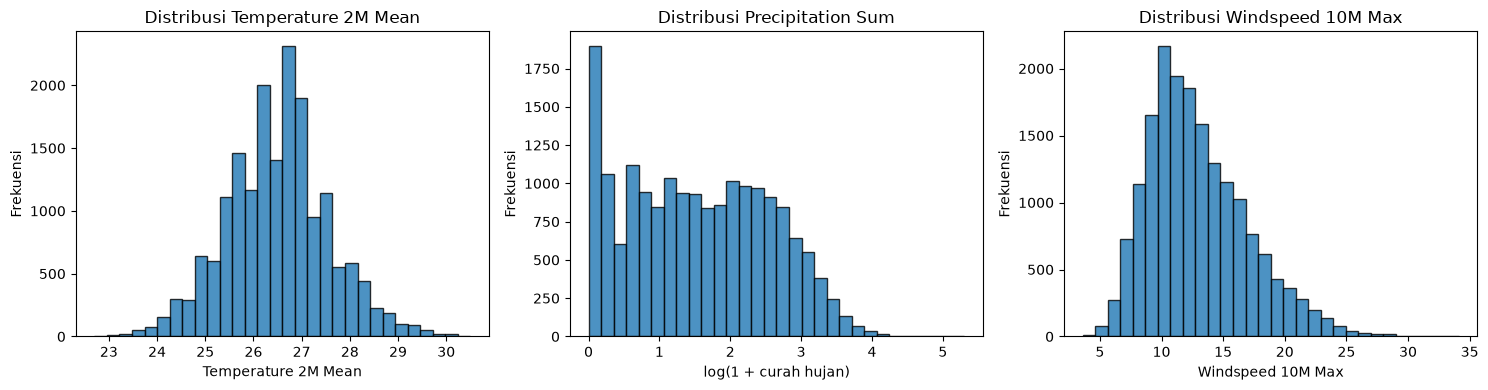

In [7]:
plot_columns = [
    column for column in [
        "temperature_2m_mean",
        "precipitation_sum",
        "windspeed_10m_max",
    ]
    if column in df.columns and df[column].notna().any()
]

if plot_columns:
    fig, axes = plt.subplots(1, len(plot_columns), figsize=(5 * len(plot_columns), 4))
    if len(plot_columns) == 1:
        axes = [axes]
    for ax, column in zip(axes, plot_columns):
        values = df[column].dropna()
        if column == "precipitation_sum":
            values = np.log1p(values.clip(lower=0))
            label = "log(1 + curah hujan)"
        else:
            label = column.replace("_", " ").title()
        ax.hist(values, bins=30, edgecolor="black", alpha=0.8)
        ax.set_title(f"Distribusi {column.replace('_', ' ').title()}")
        ax.set_xlabel(label)
        ax.set_ylabel("Frekuensi")
    plt.tight_layout()
    plt.show()

## 5. Pola cuaca berdasarkan bulan

Data dikelompokkan berdasarkan bulan kalender. Nilai yang ditampilkan adalah rata-rata per baris kota-hari dalam dataset, bukan total curah hujan seluruh Provinsi Banten. Dengan begitu, bulan dengan lebih banyak kota atau hari tidak otomatis dibaca sebagai total hujan wilayah.

,temperature_2m_mean,precipitation_sum,windspeed_10m_max
Jan,25.886,10.406,14.295
Feb,25.863,10.646,13.386
Mar,26.137,9.083,13.383
Apr,26.473,7.250,12.123
May,26.770,6.160,10.903
Jun,26.320,5.039,10.600
Jul,26.462,3.184,11.711
Aug,26.831,2.919,12.543
Sep,27.014,4.094,13.164
Oct,27.224,5.192,13.671


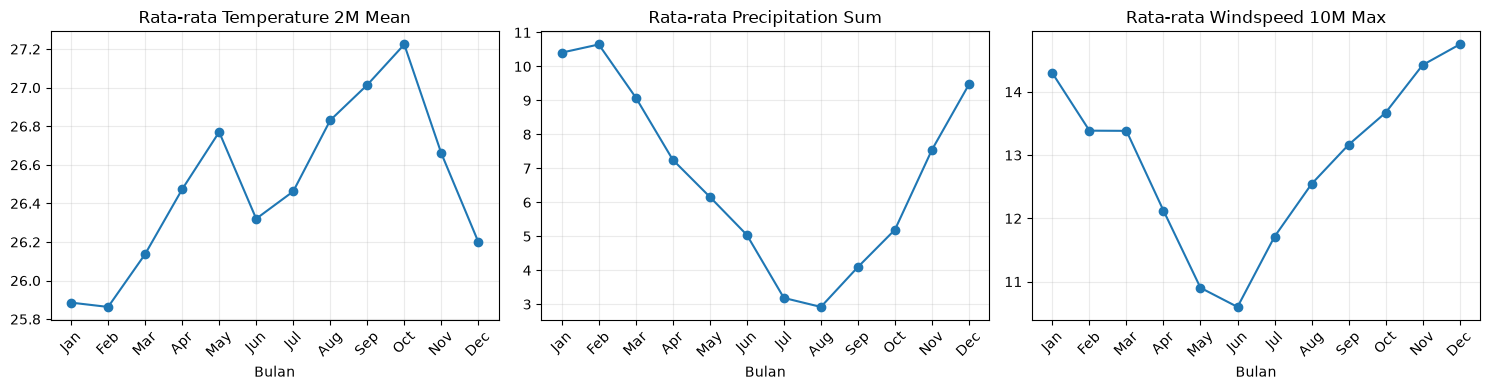

In [8]:
monthly_metrics = [
    column for column in [
        "temperature_2m_mean",
        "precipitation_sum",
        "windspeed_10m_max",
    ]
    if column in df.columns
]

df_month = df.copy()
df_month["month_number"] = df_month["date"].dt.month
monthly_profile = (
    df_month.groupby("month_number")[monthly_metrics]
    .mean()
    .reindex(range(1, 13))
)
monthly_profile.index = [calendar.month_abbr[index] for index in monthly_profile.index]
display(monthly_profile)

if monthly_metrics:
    fig, axes = plt.subplots(1, len(monthly_metrics), figsize=(5 * len(monthly_metrics), 4))
    if len(monthly_metrics) == 1:
        axes = [axes]
    for ax, column in zip(axes, monthly_metrics):
        ax.plot(monthly_profile.index, monthly_profile[column], marker="o")
        ax.set_title(f"Rata-rata {column.replace('_', ' ').title()}")
        ax.set_xlabel("Bulan")
        ax.tick_params(axis="x", rotation=45)
        ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 6. Perbandingan antar kota

Ringkasan kota menggunakan rata-rata suhu, rata-rata curah hujan per baris kota-hari, median kecepatan angin maksimum, dan persentase hari dengan curah hujan di atas 0,1 mm. Persentase hari hujan dan kategori intensitas merupakan definisi eksplorasi yang dipakai dalam notebook ini.

,records,temperature_2m_mean,precipitation_sum,windspeed_10m_max,wet_day_percent
city,,,,,
Kab. Pandeglang,2555,25.365,6.535,9.700,91.937
Kota Cilegon,2555,26.563,6.538,13.500,91.507
Kota Serang,2555,27.148,5.309,12.600,89.550
Kota Tangerang,2555,26.727,7.371,12.300,90.294
Provinsi Banten (Titik Tengah),2555,26.325,6.618,12.900,87.280
Rangkasbitung (Lebak),2555,26.493,7.102,13.000,86.693
Tangerang Selatan,2555,26.814,7.608,12.100,88.454


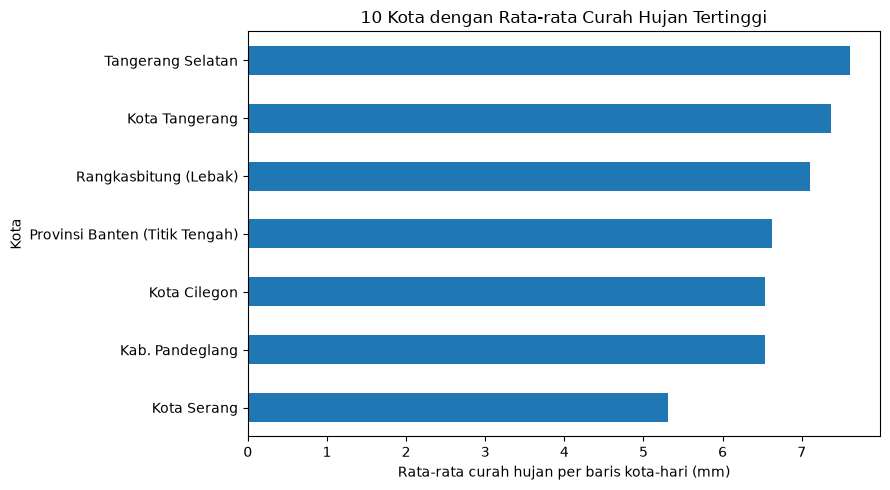

In [9]:
aggregation = {}
if "temperature_2m_mean" in df.columns:
    aggregation["temperature_2m_mean"] = "mean"
if "precipitation_sum" in df.columns:
    aggregation["precipitation_sum"] = "mean"
if "windspeed_10m_max" in df.columns:
    aggregation["windspeed_10m_max"] = "median"

city_agg = {"date": "count", **aggregation}
city_summary = (
    df.groupby("city").agg(city_agg)
    .rename(columns={"date": "records"})
)

if "precipitation_sum" in df.columns:
    wet_day_rate = (
        df.assign(is_wet_day=df["precipitation_sum"] > 0.1)
        .groupby("city")["is_wet_day"]
        .mean()
        .mul(100)
        .rename("wet_day_percent")
    )
    city_summary = city_summary.join(wet_day_rate)

display(city_summary.sort_values("records", ascending=False).head(15))

if "precipitation_sum" in city_summary.columns:
    top_rain = city_summary.sort_values("precipitation_sum", ascending=False).head(10)
    ax = top_rain["precipitation_sum"].sort_values().plot(
        kind="barh", figsize=(9, 5), title="10 Kota dengan Rata-rata Curah Hujan Tertinggi"
    )
    ax.set_xlabel("Rata-rata curah hujan per baris kota-hari (mm)")
    ax.set_ylabel("Kota")
    plt.tight_layout()
    plt.show()

## 7. Analisis korelasi

Korelasi Pearson digunakan sebagai gambaran hubungan linear antarvariabel numerik. Korelasi tidak membuktikan sebab-akibat. Kolom `cape_proxy_radiation` diperlakukan sebagai fitur proxy sebagaimana penamaannya dalam kode aplikasi, bukan otomatis dianggap sebagai pengukuran radiasi atau CAPE yang tervalidasi.

,temperature_2m_mean,precipitation_sum,windspeed_10m_max,cape_proxy_radiation
temperature_2m_mean,1.000,-0.442,0.132,0.640
precipitation_sum,-0.442,1.000,-0.026,-0.504
windspeed_10m_max,0.132,-0.026,1.000,0.133
cape_proxy_radiation,0.640,-0.504,0.133,1.000


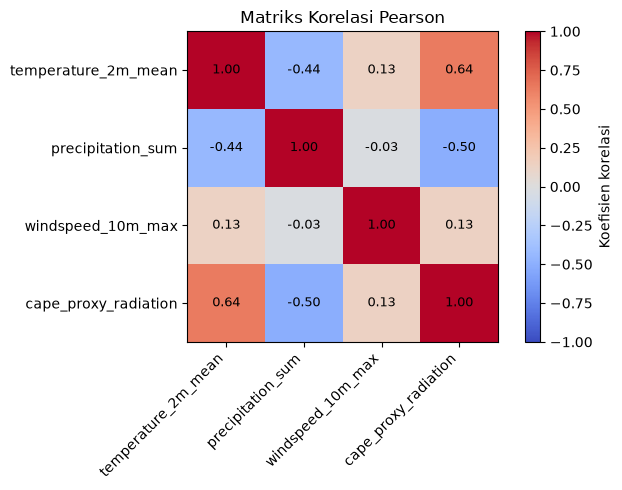

In [10]:
correlation_columns = [
    column for column in [
        "temperature_2m_mean",
        "precipitation_sum",
        "windspeed_10m_max",
        "cape_proxy_radiation",
    ]
    if column in df.columns and pd.api.types.is_numeric_dtype(df[column])
]
correlation_columns = [
    column for column in correlation_columns
    if df[column].notna().sum() > 1 and df[column].nunique(dropna=True) > 1
]

if len(correlation_columns) >= 2:
    correlation_matrix = df[correlation_columns].corr(method="pearson")
    display(correlation_matrix)

    fig, ax = plt.subplots(figsize=(7, 5))
    image = ax.imshow(correlation_matrix, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(correlation_columns)))
    ax.set_yticks(range(len(correlation_columns)))
    ax.set_xticklabels(correlation_columns, rotation=45, ha="right")
    ax.set_yticklabels(correlation_columns)
    for row in range(len(correlation_columns)):
        for column in range(len(correlation_columns)):
            ax.text(column, row, f"{correlation_matrix.iloc[row, column]:.2f}",
                    ha="center", va="center", fontsize=9)
    ax.set_title("Matriks Korelasi Pearson")
    fig.colorbar(image, ax=ax, label="Koefisien korelasi")
    plt.tight_layout()
    plt.show()
else:
    print("Kolom numerik bervariasi tidak cukup untuk menghitung korelasi.")

## 8. Pemeriksaan nilai ekstrem dengan metode IQR

Metode interquartile range (IQR) digunakan untuk menandai nilai yang jauh dari sebaran tengah. Baris yang terdeteksi **tidak dihapus**. Nilai tersebut dapat merupakan kejadian cuaca ekstrem yang valid atau kesalahan pencatatan, sehingga perlu divalidasi dengan sumber data.

In [11]:
outlier_rows = []
for column in climate_columns:
    values = df[column].dropna()
    if len(values) < 4:
        continue
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = int(((values < lower_bound) | (values > upper_bound)).sum())
    outlier_rows.append({
        "column": column,
        "lower_iqr_bound": lower_bound,
        "upper_iqr_bound": upper_bound,
        "flagged_values": outlier_count,
        "flagged_percent": outlier_count / len(values) * 100,
    })

outlier_report = pd.DataFrame(outlier_rows)
display(outlier_report)

,column,lower_iqr_bound,upper_iqr_bound,flagged_values,flagged_percent
0,temperature_2m_mean,23.850,29.050,351,1.963
1,precipitation_sum,-11.900,22.500,961,5.373
2,windspeed_10m_max,2.050,23.250,295,1.649
3,cape_proxy_radiation,9.470,27.870,634,3.545


## 9. Ringkasan insight otomatis

Insight di bawah dihitung dari dataset yang berhasil dibaca. Hasilnya bersifat deskriptif dan dapat berubah ketika dataset diperbarui. Periksa kembali cakupan tanggal dan jumlah catatan tiap kota sebelum membandingkan hasil.

In [12]:
print("RINGKASAN DATA CUACA BANTEN")
print("=" * 42)
print(f"Rentang tanggal : {date_start:%Y-%m-%d} sampai {date_end:%Y-%m-%d}")
print(f"Jumlah kota     : {df['city'].nunique()}")
print(f"Jumlah catatan  : {len(df):,}")

if "temperature_2m_mean" in df.columns:
    print(f"Rata-rata suhu  : {df['temperature_2m_mean'].mean():.2f} °C")

if "precipitation_sum" in df.columns:
    print(f"Rata-rata hujan : {df['precipitation_sum'].mean():.2f} mm per catatan kota-hari")
    city_rain_mean = df.groupby("city")["precipitation_sum"].mean().dropna()
    if not city_rain_mean.empty:
        print(f"Rata-rata hujan tertinggi: {city_rain_mean.idxmax()} ({city_rain_mean.max():.2f} mm)")

if "temperature_2m_mean" in df.columns:
    city_temp_mean = df.groupby("city")["temperature_2m_mean"].mean().dropna()
    if not city_temp_mean.empty:
        print(f"Rata-rata suhu tertinggi : {city_temp_mean.idxmax()} ({city_temp_mean.max():.2f} °C)")

if "precipitation_sum" in monthly_profile.columns:
    wettest_month = monthly_profile["precipitation_sum"].idxmax()
    print(f"Bulan dengan rata-rata hujan tertinggi: {wettest_month}")

print("\nCatatan: insight ini bukan prediksi dan bukan bukti hubungan sebab-akibat.")

RINGKASAN DATA CUACA BANTEN
Rentang tanggal : 2019-01-03 sampai 2025-12-31
Jumlah kota     : 7
Jumlah catatan  : 17,885
Rata-rata suhu  : 26.49 °C
Rata-rata hujan : 6.73 mm per catatan kota-hari
Rata-rata hujan tertinggi: Tangerang Selatan (7.61 mm)
Rata-rata suhu tertinggi : Kota Serang (27.15 °C)
Bulan dengan rata-rata hujan tertinggi: Feb

Catatan: insight ini bukan prediksi dan bukan bukti hubungan sebab-akibat.


## 10. Kelengkapan cakupan tanggal per kota

Bagian ini memeriksa apakah setiap kota memiliki satu catatan untuk setiap tanggal di dalam rentang dataset. Pemeriksaan ini berbeda dari pemeriksaan missing values: sebuah kolom bisa tidak memiliki nilai kosong, tetapi masih mungkin ada pasangan kota-tanggal yang tidak tercatat.

In [13]:
expected_dates = pd.date_range(date_start.normalize(), date_end.normalize(), freq="D")
coverage_rows = []

df_for_coverage = df.assign(date_only=df["date"].dt.normalize())
duplicate_city_date_rows = int(
    df_for_coverage.duplicated(subset=["city", "date_only"], keep=False).sum()
)

for city, group in df_for_coverage.groupby("city"):
    observed_dates = pd.DatetimeIndex(group["date_only"].drop_duplicates())
    missing_dates = expected_dates.difference(observed_dates)
    coverage_rows.append({
        "city": city,
        "records": len(group),
        "unique_dates": len(observed_dates),
        "expected_dates": len(expected_dates),
        "missing_dates": len(missing_dates),
        "coverage_percent": len(observed_dates) / len(expected_dates) * 100,
        "duplicate_city_date_rows": int(
            group.duplicated(subset=["date_only"], keep=False).sum()
        ),
        "first_missing_dates": ", ".join(
            date.strftime("%Y-%m-%d") for date in missing_dates[:5]
        ),
    })

city_day_coverage = pd.DataFrame(coverage_rows).sort_values("city")
display(city_day_coverage)

print(f"Total pasangan kota-tanggal duplikat: {duplicate_city_date_rows:,}")
print(
    "Catatan: cakupan 100% berarti setiap kota memiliki satu tanggal unik "
    "untuk setiap hari dalam rentang analisis; pemeriksaan duplikat tetap dilaporkan terpisah."
)

,city,records,unique_dates,expected_dates,missing_dates,coverage_percent,duplicate_city_date_rows,first_missing_dates
0,Kab. Pandeglang,2555,2555,2555,0,100.000,0,
1,Kota Cilegon,2555,2555,2555,0,100.000,0,
2,Kota Serang,2555,2555,2555,0,100.000,0,
3,Kota Tangerang,2555,2555,2555,0,100.000,0,
4,Provinsi Banten (Titik Tengah),2555,2555,2555,0,100.000,0,
5,Rangkasbitung (Lebak),2555,2555,2555,0,100.000,0,
6,Tangerang Selatan,2555,2555,2555,0,100.000,0,


Total pasangan kota-tanggal duplikat: 0
Catatan: cakupan 100% berarti setiap kota memiliki satu tanggal unik untuk setiap hari dalam rentang analisis; pemeriksaan duplikat tetap dilaporkan terpisah.


## 11. Tren tahunan

Rata-rata tahunan membantu melihat variasi dari tahun ke tahun. Nilai ini tetap merupakan ringkasan deskriptif; perubahan tahunan tidak boleh langsung disebut sebagai tren iklim jangka panjang tanpa pengujian statistik, konteks wilayah, dan verifikasi sumber data.

,temperature_2m_mean,precipitation_sum,windspeed_10m_max
year,,,
2019,26.789,4.811,12.655
2020,26.394,8.041,12.396
2021,26.161,6.947,12.232
2022,26.017,7.239,13.045
2023,26.807,5.086,13.512
2024,26.895,7.013,13.103
2025,26.373,7.927,13.440


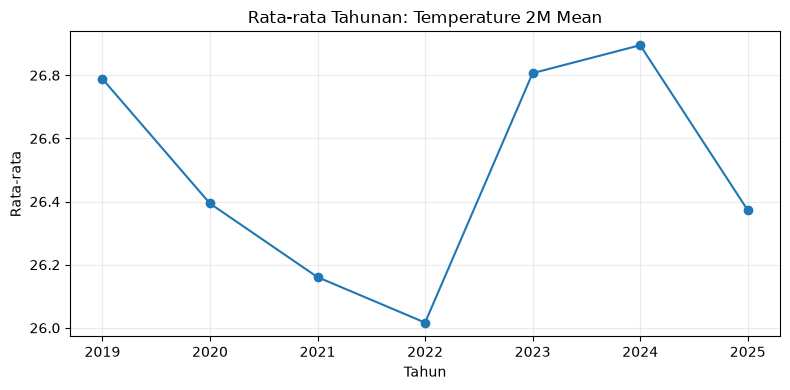

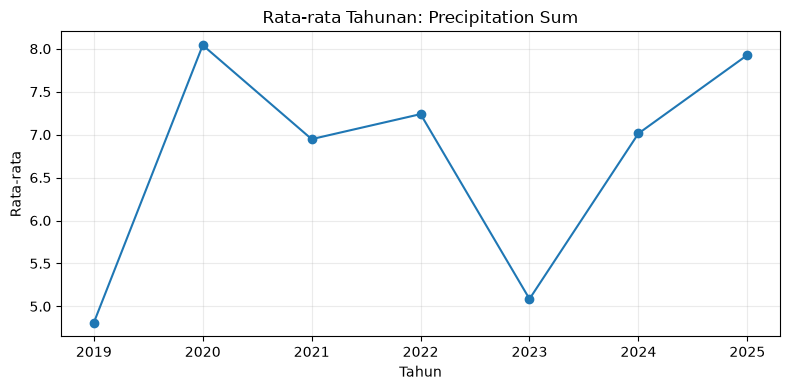

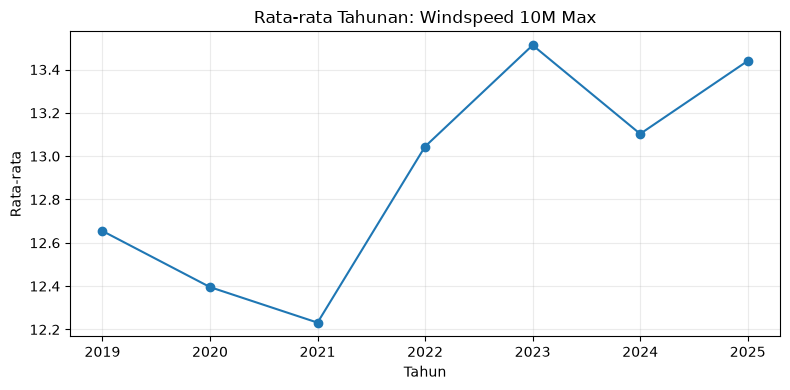

In [14]:
annual_metrics = [
    column for column in [
        "temperature_2m_mean",
        "precipitation_sum",
        "windspeed_10m_max",
    ]
    if column in df.columns
]

df_year = df.assign(year=df["date"].dt.year)
annual_weather_profile = (
    df_year.groupby("year")[annual_metrics]
    .mean()
    .sort_index()
)
display(annual_weather_profile)

for column in annual_metrics:
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.plot(
        annual_weather_profile.index.astype(str),
        annual_weather_profile[column],
        marker="o",
    )
    ax.set_title(f"Rata-rata Tahunan: {column.replace('_', ' ').title()}")
    ax.set_xlabel("Tahun")
    ax.set_ylabel("Rata-rata")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

## 12. Pola curah hujan menurut kota dan bulan

Heatmap berikut membandingkan rata-rata curah hujan per kota untuk setiap bulan kalender. Angka bukan total akumulasi hujan bulanan seluruh wilayah.

month_number,1,2,3,4,5,6,7,8,9,10,11,12
city,,,,,,,,,,,,
Kab. Pandeglang,8.231,9.172,8.482,7.402,6.558,5.463,3.553,2.931,4.161,5.585,7.780,9.302
Kota Cilegon,11.384,9.345,8.446,6.113,6.019,4.812,3.641,3.188,3.626,4.749,7.369,9.915
Kota Serang,8.357,8.647,6.819,5.683,4.290,4.066,2.770,2.287,2.963,3.959,6.184,7.923
Kota Tangerang,12.112,11.816,10.137,8.389,6.210,6.166,3.497,3.355,4.481,5.407,8.089,9.147
Provinsi Banten (Titik Tengah),10.818,11.051,9.885,7.108,5.628,4.056,2.480,2.016,3.708,5.049,7.470,10.443
Rangkasbitung (Lebak),9.947,11.041,9.468,7.615,7.446,5.612,3.193,3.057,5.262,5.641,7.485,9.745
Tangerang Selatan,11.993,13.452,10.344,8.442,6.967,5.100,3.158,3.601,4.456,5.954,8.438,9.818


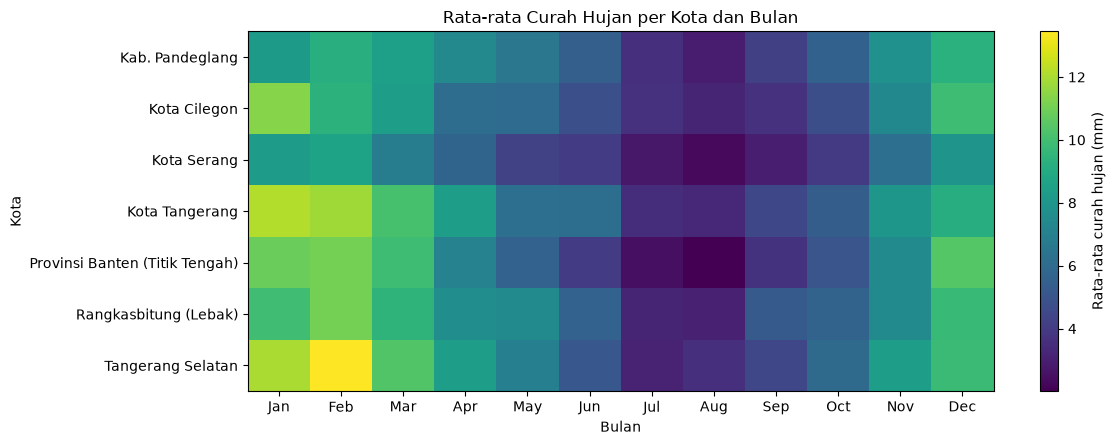

In [15]:
monthly_city_precipitation = (
    df.assign(month_number=df["date"].dt.month)
    .pivot_table(
        index="city",
        columns="month_number",
        values="precipitation_sum",
        aggfunc="mean",
    )
    .reindex(columns=range(1, 13))
)

display(monthly_city_precipitation)

fig, ax = plt.subplots(figsize=(12, max(4, 0.65 * len(monthly_city_precipitation))))
heatmap = ax.imshow(
    monthly_city_precipitation,
    aspect="auto",
    interpolation="nearest",
)
ax.set_xticks(range(12))
ax.set_xticklabels([calendar.month_abbr[m] for m in range(1, 13)])
ax.set_yticks(range(len(monthly_city_precipitation.index)))
ax.set_yticklabels(monthly_city_precipitation.index)
ax.set_title("Rata-rata Curah Hujan per Kota dan Bulan")
ax.set_xlabel("Bulan")
ax.set_ylabel("Kota")
fig.colorbar(heatmap, ax=ax, label="Rata-rata curah hujan (mm)")
plt.tight_layout()
plt.show()

## 13. Distribusi curah hujan dan frekuensi hari hujan

Selain rata-rata curah hujan, bagian ini memeriksa median, persentil tinggi, dan frekuensi hari hujan. Definisi hari hujan di notebook ini memakai ambang eksplorasi **lebih dari 0,1 mm**; ambang tersebut bukan klaim kategori resmi BMKG.

,quantile,precipitation_sum_mm
0,0.000,0.000
1,0.250,1.000
2,0.500,3.600
3,0.750,9.600
4,0.900,17.300
5,0.950,23.200
6,0.990,37.300
7,1.000,200.300


,records,mean_rain_mm,median_rain_mm,wet_days,wet_day_percent,mean_rain_on_wet_days_mm
city,,,,,,
Tangerang Selatan,2555,7.608,4.800,2260,88.454,8.598
Kota Tangerang,2555,7.371,4.400,2307,90.294,8.160
Rangkasbitung (Lebak),2555,7.102,3.700,2215,86.693,8.188
Provinsi Banten (Titik Tengah),2555,6.618,3.200,2230,87.280,7.580
Kota Cilegon,2555,6.538,3.300,2338,91.507,7.142
Kab. Pandeglang,2555,6.535,3.700,2349,91.937,7.105
Kota Serang,2555,5.309,2.400,2288,89.550,5.924


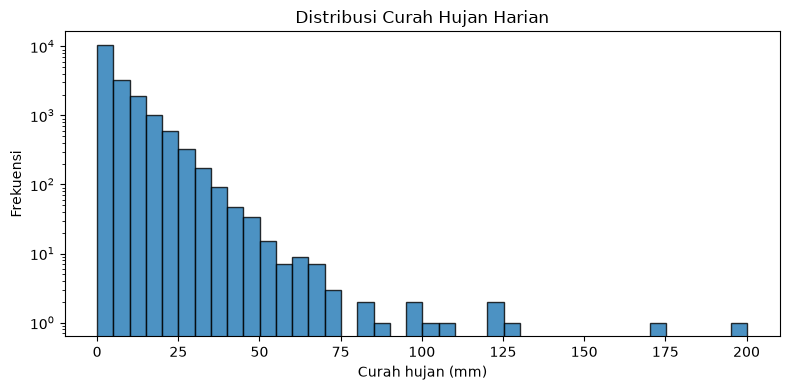

In [16]:
if "precipitation_sum" in df.columns:
    rain_values = df["precipitation_sum"].dropna()
    rainfall_quantiles = (
        rain_values.quantile([0, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99, 1.00])
        .rename_axis("quantile")
        .reset_index(name="precipitation_sum_mm")
    )
    display(rainfall_quantiles)

    wet_day_threshold = 0.1
    df_rain = df.assign(
        is_wet_day=df["precipitation_sum"] > wet_day_threshold
    )
    rainfall_by_city = (
        df_rain.groupby("city")
        .agg(
            records=("precipitation_sum", "count"),
            mean_rain_mm=("precipitation_sum", "mean"),
            median_rain_mm=("precipitation_sum", "median"),
            wet_days=("is_wet_day", "sum"),
            wet_day_percent=("is_wet_day", "mean"),
        )
    )
    rainfall_by_city["wet_day_percent"] *= 100
    rainfall_by_city["mean_rain_on_wet_days_mm"] = (
        df_rain[df_rain["is_wet_day"]]
        .groupby("city")["precipitation_sum"]
        .mean()
    )
    display(rainfall_by_city.sort_values("mean_rain_mm", ascending=False))

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(rain_values.clip(lower=0), bins=40, edgecolor="black", alpha=0.8)
    ax.set_title("Distribusi Curah Hujan Harian")
    ax.set_xlabel("Curah hujan (mm)")
    ax.set_ylabel("Frekuensi")
    ax.set_yscale("log")
    plt.tight_layout()
    plt.show()
else:
    rainfall_quantiles = pd.DataFrame()
    rainfall_by_city = pd.DataFrame()
    print("Kolom precipitation_sum tidak tersedia.")

## 14. Korelasi Spearman dan pola hubungan antarvariabel

Pearson mengukur hubungan linear, sedangkan Spearman mengukur hubungan berdasarkan peringkat dan dapat melengkapi pembacaan ketika distribusi curah hujan tidak simetris. Variabel lag, rolling, dan fitur turunan tidak dimasukkan ke matriks ini agar pembacaan awal berfokus pada variabel cuaca utama. Kedua korelasi tetap bukan bukti sebab-akibat.

Korelasi Pearson


,temperature_2m_mean,precipitation_sum,windspeed_10m_max,cape_proxy_radiation
temperature_2m_mean,1.000,-0.442,0.132,0.640
precipitation_sum,-0.442,1.000,-0.026,-0.504
windspeed_10m_max,0.132,-0.026,1.000,0.133
cape_proxy_radiation,0.640,-0.504,0.133,1.000


Korelasi Spearman


,temperature_2m_mean,precipitation_sum,windspeed_10m_max,cape_proxy_radiation
temperature_2m_mean,1.000,-0.522,0.133,0.624
precipitation_sum,-0.522,1.000,-0.078,-0.552
windspeed_10m_max,0.133,-0.078,1.000,0.172
cape_proxy_radiation,0.624,-0.552,0.172,1.000


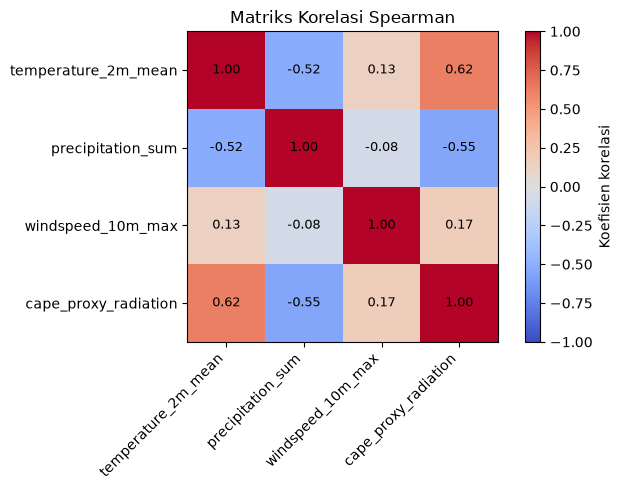

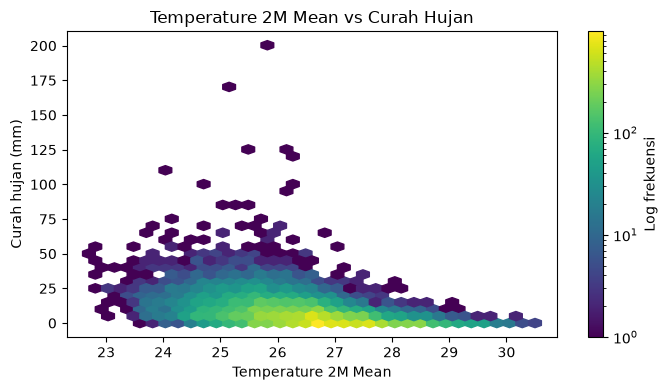

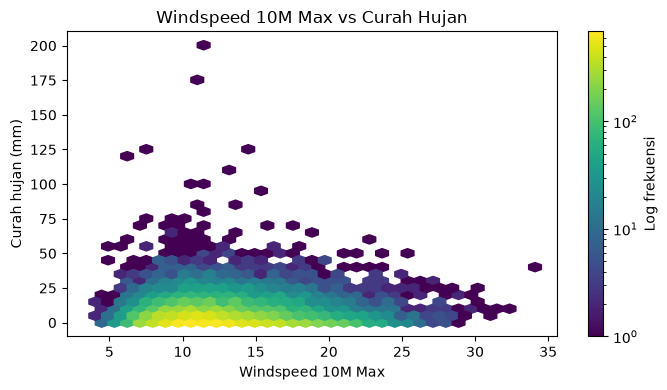

In [17]:
base_weather_columns = [
    column for column in [
        "temperature_2m_mean",
        "precipitation_sum",
        "windspeed_10m_max",
        "cape_proxy_radiation",
    ]
    if column in df.columns and pd.api.types.is_numeric_dtype(df[column])
]
base_weather_columns = [
    column for column in base_weather_columns
    if df[column].notna().sum() > 1 and df[column].nunique(dropna=True) > 1
]

if len(base_weather_columns) >= 2:
    pearson_weather = df[base_weather_columns].corr(method="pearson")
    spearman_weather = df[base_weather_columns].corr(method="spearman")

    print("Korelasi Pearson")
    display(pearson_weather)
    print("Korelasi Spearman")
    display(spearman_weather)

    fig, ax = plt.subplots(figsize=(7, 5))
    image = ax.imshow(spearman_weather, vmin=-1, vmax=1, cmap="coolwarm")
    ax.set_xticks(range(len(base_weather_columns)))
    ax.set_yticks(range(len(base_weather_columns)))
    ax.set_xticklabels(base_weather_columns, rotation=45, ha="right")
    ax.set_yticklabels(base_weather_columns)
    for row in range(len(base_weather_columns)):
        for column in range(len(base_weather_columns)):
            ax.text(
                column, row, f"{spearman_weather.iloc[row, column]:.2f}",
                ha="center", va="center", fontsize=9
            )
    ax.set_title("Matriks Korelasi Spearman")
    fig.colorbar(image, ax=ax, label="Koefisien korelasi")
    plt.tight_layout()
    plt.show()
else:
    pearson_weather = pd.DataFrame()
    spearman_weather = pd.DataFrame()
    print("Kolom cuaca numerik bervariasi tidak cukup untuk korelasi.")

for x_column in ["temperature_2m_mean", "windspeed_10m_max"]:
    if x_column in df.columns and "precipitation_sum" in df.columns:
        plot_data = df[[x_column, "precipitation_sum"]].dropna()
        if not plot_data.empty:
            fig, ax = plt.subplots(figsize=(7, 4))
            points = ax.hexbin(
                plot_data[x_column],
                plot_data["precipitation_sum"],
                gridsize=35,
                mincnt=1,
                bins="log",
            )
            fig.colorbar(points, ax=ax, label="Log frekuensi")
            ax.set_title(
                f"{x_column.replace('_', ' ').title()} vs Curah Hujan"
            )
            ax.set_xlabel(x_column.replace("_", " ").title())
            ax.set_ylabel("Curah hujan (mm)")
            plt.tight_layout()
            plt.show()

## 15. Pemeriksaan outlier per kota

IQR global dapat menandai perbedaan antarwilayah sebagai outlier karena distribusi cuaca setiap kota mungkin tidak sama. Tabel berikut menghitung batas IQR secara terpisah untuk setiap kota. Hasilnya tetap berupa penanda untuk ditinjau, bukan instruksi menghapus data.

In [18]:
city_outlier_rows = []
for city, group in df.groupby("city"):
    for column in climate_columns:
        values = group[column].dropna()
        if len(values) < 4:
            continue
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
        flagged_count = int(
            ((values < lower_bound) | (values > upper_bound)).sum()
        )
        city_outlier_rows.append({
            "city": city,
            "column": column,
            "lower_iqr_bound": lower_bound,
            "upper_iqr_bound": upper_bound,
            "flagged_values": flagged_count,
            "flagged_percent": flagged_count / len(values) * 100,
        })

city_outlier_report = pd.DataFrame(city_outlier_rows)
display(
    city_outlier_report.sort_values(
        ["column", "flagged_percent"], ascending=[True, False]
    )
)

,city,column,lower_iqr_bound,upper_iqr_bound,flagged_values,flagged_percent
7,Kota Cilegon,cape_proxy_radiation,10.583,28.402,116,4.540
15,Kota Tangerang,cape_proxy_radiation,10.352,27.613,116,4.540
11,Kota Serang,cape_proxy_radiation,10.400,27.760,115,4.501
27,Tangerang Selatan,cape_proxy_radiation,9.887,27.428,96,3.757
23,Rangkasbitung (Lebak),cape_proxy_radiation,9.192,27.892,80,3.131
19,Provinsi Banten (Titik Tengah),cape_proxy_radiation,8.622,27.643,73,2.857
3,Kab. Pandeglang,cape_proxy_radiation,8.442,27.103,70,2.740
9,Kota Serang,precipitation_sum,-8.650,16.550,176,6.888
17,Provinsi Banten (Titik Tengah),precipitation_sum,-11.800,21.800,171,6.693
5,Kota Cilegon,precipitation_sum,-10.825,20.975,152,5.949


## Catatan interpretasi

- Rata-rata curah hujan dihitung per catatan kota-hari, bukan total hujan seluruh Provinsi Banten.
- Persentase hari hujan memakai ambang eksplorasi >0,1 mm.
- Outlier IQR perlu ditinjau bersama satuan, sumber, dan konteks meteorologis; jangan otomatis dihapus.
- Korelasi Pearson dan Spearman bersifat deskriptif dan tidak menjelaskan hubungan sebab-akibat.
- Variabel `cape_proxy_radiation` tetap diperlakukan sebagai fitur proxy sampai definisi dan satuannya dikonfirmasi dari data dictionary.
- Perbandingan tahunan belum cukup untuk menyimpulkan perubahan iklim atau tren jangka panjang tanpa analisis statistik dan metadata tambahan.

## 16. Ekspor hasil analisis

Notebook menyimpan ringkasan kualitas data dan ringkasan per kota ke folder `analysis_outputs/` pada root repository. Folder hasil tidak perlu dimasukkan ke GitHub karena seluruh hasil dapat dibuat ulang dengan menjalankan notebook.

In [19]:
OUTPUT_DIR = DATA_PATH.parent.parent / "analysis_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(OUTPUT_DIR / "data_quality_report.csv", index=True)
city_summary.to_csv(OUTPUT_DIR / "city_weather_summary.csv", index=True)
monthly_profile.to_csv(OUTPUT_DIR / "monthly_weather_profile.csv", index=True)
if not outlier_report.empty:
    outlier_report.to_csv(OUTPUT_DIR / "outlier_iqr_report.csv", index=False)

print(f"Hasil analisis tersimpan di: {OUTPUT_DIR}")
print("File: data_quality_report.csv, city_weather_summary.csv, monthly_weather_profile.csv")
if not outlier_report.empty:
    print("Tambahan: outlier_iqr_report.csv")

Hasil analisis tersimpan di: C:\Users\advan\Downloads\weather-ai-banten-github\analysis_outputs
File: data_quality_report.csv, city_weather_summary.csv, monthly_weather_profile.csv
Tambahan: outlier_iqr_report.csv


In [20]:
extra_exports = {
    "city_day_coverage_report.csv": city_day_coverage,
    "annual_weather_profile.csv": annual_weather_profile,
    "monthly_city_precipitation.csv": monthly_city_precipitation,
    "rainfall_quantiles.csv": rainfall_quantiles,
    "rainfall_by_city.csv": rainfall_by_city,
    "city_outlier_report.csv": city_outlier_report,
}

if not pearson_weather.empty:
    pearson_weather.to_csv(OUTPUT_DIR / "weather_correlation_pearson.csv")
if not spearman_weather.empty:
    spearman_weather.to_csv(OUTPUT_DIR / "weather_correlation_spearman.csv")

for filename, result in extra_exports.items():
    if result is not None and not result.empty:
        result.to_csv(OUTPUT_DIR / filename, index=True)

print("Tambahan output:")
for filename, result in extra_exports.items():
    if result is not None and not result.empty:
        print(f"- {filename}")
if not pearson_weather.empty:
    print("- weather_correlation_pearson.csv")
if not spearman_weather.empty:
    print("- weather_correlation_spearman.csv")

Tambahan output:
- city_day_coverage_report.csv
- annual_weather_profile.csv
- monthly_city_precipitation.csv
- rainfall_quantiles.csv
- rainfall_by_city.csv
- city_outlier_report.csv
- weather_correlation_pearson.csv
- weather_correlation_spearman.csv


## Kesimpulan dan pekerjaan lanjutan

Gunakan tabel dan grafik di atas untuk menulis kesimpulan berdasarkan nilai aktual yang muncul saat notebook dijalankan. Pengembangan berikutnya yang disarankan:
1. Tambahkan data dictionary berisi definisi, satuan, sumber, dan frekuensi setiap variabel.
2. Validasi nilai ekstrem dengan sumber data cuaca yang tepercaya.
3. Buat evaluasi model terpisah menggunakan data uji yang tidak dipakai saat training, lalu laporkan MAE dan RMSE untuk suhu serta metrik yang sesuai untuk curah hujan.
4. Hindari kebocoran data waktu dengan memisahkan data training dan testing berdasarkan kronologi, bukan pengacakan baris.